# 8. Estimates by catalog and century

The USTC and the BNE are different catalogs: the USTC ends in 1700, the BNE in 1800, and about 22,700 BNE records describe
editions that are also in the USTC. So I never add them up: every figure here is for one catalog and one century.

Each estimate comes from the sample of notebooks 6 and 7b, classified by the open model in notebooks 7 and 7b. In each cell
(catalog × century × lexicon class) I take the share of the sample in a group and multiply it by the number of catalog records in
the cell; then I add up the cells. The 95% interval comes from the size of the sample in each cell. The 744 USTC records without a
year stay out of the century figures. The last cell compares these estimates with the classifier of notebook 7c.

---

# 8. Estimaciones por catálogo y siglo

El USTC y la BNE son catálogos distintos: el USTC termina en 1700, la BNE en 1800, y unos 22.700 registros de la BNE describen
ediciones que también están en el USTC. Por eso nunca los sumo: cada cifra de acá es de un catálogo y un siglo.

Cada estimación sale de la muestra de los notebooks 6 y 7b, clasificada por el modelo abierto en los notebooks 7 y 7b. En cada
casilla (catálogo × siglo × clase del léxico) tomo la proporción de la muestra que cae en un grupo y la multiplico por la cantidad
de registros del catálogo en esa casilla; después sumo las casillas. El intervalo del 95 % depende del tamaño de la muestra en
cada casilla. Los 744 registros del USTC sin año quedan fuera de las cifras por siglo. La última celda compara estas estimaciones
con el clasificador del notebook 7c.

In [1]:
# Celda 1
# Paths and parameters:
%cd "E:/No sincroniza/Software desarrollado/spanish-imprints-counts"
DATA = "E:/Datos/spanish_imprints"
CATALOG = DATA + "/catalog.tsv"                               # From notebook 3.
BNE_CATALOG = DATA + "/bne/monoantiguas-UTF8.zip"           # Downloaded by hand; only its "url" field is used here.
CATALOG_PREDICTIONS = DATA + "/ml_catalog_predictions.tsv"    # From notebook 7c, only for the last cell.
SAMPLE = "data/llm_catalog_sample.tsv"                        # From notebook 6.
SAMPLE_RESULTS = "data/llm_catalog_sample_results.tsv"        # From notebook 7.
EXTRA_SAMPLE = "data/llm_bne16_extra_sample.tsv"              # From notebook 6.
EXTRA_RESULTS = "data/llm_bne16_extra_results.tsv"            # From notebook 7b.
SAMPLE_PREDICTIONS = "data/ml_sample_predictions.tsv"         # From notebook 7c, only for the last cell.
FIGURES = "figures"
MIN_PAGES = 48
CATEGORIES = ["espiritual", "predicable", "historia_sacra", "teologia_moral", "catecismo",
              "teologia", "biblia", "liturgia", "gobierno_religioso", "no_religioso"]
PASTORAL = ["espiritual", "predicable", "historia_sacra", "teologia_moral", "catecismo"]
# English names for tables and figures ("gobierno_religioso" also holds lawsuits and other legal print):
ENGLISH = {"espiritual": "Spiritual", "predicable": "Preaching", "historia_sacra": "Sacred history",
           "teologia_moral": "Moral theology", "catecismo": "Catechisms", "teologia": "Theology", "biblia": "Bible",
           "liturgia": "Liturgy", "gobierno_religioso": "Church government and legal", "no_religioso": "Not religious"}
CENTURIES = {"ustc": ["16th", "17th"], "bne": ["16th", "17th", "18th"]}
NAMES = {"ustc": "USTC", "bne": "BNE"}
# Figures: black background, Montserrat, USTC in green, BNE in white:
GREEN, WHITE, GRAY = "#3AF4A0", "#F2F2F2", "#8C8C8C"

E:\No sincroniza\Software desarrollado\spanish-imprints-counts


In [2]:
# Celda 2
import os, math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
os.makedirs(FIGURES, exist_ok=True)
os.makedirs("results", exist_ok=True)
plt.style.use("dark_background")
plt.rc("font", family="Montserrat")

catalog = pd.read_csv(CATALOG, sep="\t", dtype={"id": str})
catalog = catalog.merge(pd.read_csv(CATALOG_PREDICTIONS, sep="\t", dtype={"id": str}), on=["source", "id"])
sample = pd.read_csv(SAMPLE, sep="\t", dtype={"id": str})
sample = sample.merge(pd.read_csv(SAMPLE_RESULTS, sep="\t", dtype={"id": str}), on=["source", "id"])
extra = pd.read_csv(EXTRA_SAMPLE, sep="\t", dtype={"id": str})
extra = extra.merge(pd.read_csv(EXTRA_RESULTS, sep="\t", dtype={"id": str}), on=["source", "id"])
labeled = pd.concat([sample, extra], ignore_index=True)
labeled = labeled.merge(pd.read_csv(SAMPLE_PREDICTIONS, sep="\t", dtype={"id": str}), on=["source", "id"])
labeled = labeled.merge(catalog[["source", "id", "has_author", "jesuit_strict"]], on=["source", "id"])
print("Catalog:", len(catalog), "| sample:", len(labeled))

Catalog: 163169 | sample: 5807


## 1. How do I split each catalog into cells?

---

## 1. ¿Cómo divido cada catálogo en casillas?

In [3]:
# Celda 3
# 1567 -> "16th"; 1500 counts as sixteenth century, as in the catalogs:
def century(year):
    if pd.isna(year):
        return "no year"
    if year <= 1600:
        return "16th"
    if year <= 1700:
        return "17th"
    return "18th"

# Columns that narrow a group: every record, books of 48 pages or more, records with an author, and Jesuit authors:
for table in [catalog, labeled]:
    table["century"] = table["year"].map(century)
    table["all"] = True
    table["long"] = table["pages"] >= MIN_PAGES
    table["with_author"] = table["has_author"]
    table["jesuit"] = table["has_author"] & table["jesuit_strict"]

cells = pd.DataFrame({"catalog": catalog.groupby(["source", "century", "lexicon_class"]).size(),
                      "sample": labeled.groupby(["source", "century", "lexicon_class"]).size()})
cells

catalog  sample
source century lexicon_class                  
bne    16th    none               5191     500
               other_pastoral      451     250
               spiritual           503     250
       17th    none              31177     587
               other_pastoral     3629     236
               spiritual          1637     207
       18th    none              30314     572
               other_pastoral     4830     294
               spiritual          2669     302
ustc   16th    none               8632     148
               other_pastoral     1266      61
               spiritual          1245     138
       17th    none              56083    1078
               other_pastoral    10440     631
               spiritual          4358     538
       no year none                671      10
               other_pastoral       54       4
               spiritual            19       1

In [4]:
# Celda 4
# Estimated number of records of one catalog, in some centuries, whose category is in `categories` and whose `condition`
# column is True; and the half-width of its 95% interval. In each cell: share of the sample in the group × records of the cell:
def estimate(categories, source, centuries, condition="all"):
    total = 0
    variance = 0
    for century in centuries:
        for stratum in ["spiritual", "other_pastoral", "none"]:
            N = ((catalog["source"] == source) & (catalog["century"] == century) & (catalog["lexicon_class"] == stratum)).sum()
            rows = labeled[(labeled["source"] == source) & (labeled["century"] == century) & (labeled["lexicon_class"] == stratum)]
            p = (rows["llm_category"].isin(categories) & rows[condition]).mean()
            total = total + N * p
            variance = variance + N * N * p * (1 - p) / len(rows)
    return total, 1.96 * math.sqrt(variance)

estimate(["espiritual"], "bne", ["16th"])

(473.78600000000006, 88.9139512422618)

## 2. How many pastoral editions are there in each catalog and century?

---

## 2. ¿Cuántas ediciones pastorales hay en cada catálogo y siglo?

In [5]:
# Celda 5
# Records of each catalog and century:
universe = catalog.groupby(["source", "century"]).size().unstack(fill_value=0)
universe.index = [NAMES[s] for s in universe.index]
universe

century,16th,17th,18th,no year
BNE,6145,36443,37813,0
USTC,11143,70881,0,744


In [6]:
# Celda 6
# Pastoral books and their five categories, by catalog and century:
rows = []
for source in CENTURIES:
    for century in CENTURIES[source]:
        records = ((catalog["source"] == source) & (catalog["century"] == century)).sum()
        for name, categories in [("Pastoral", PASTORAL)] + [(ENGLISH[c], [c]) for c in PASTORAL]:
            total, margin = estimate(categories, source, [century])
            rows.append({"catalog": NAMES[source], "century": century, "group": name, "editions": round(total),
                         "low": round(total - margin), "high": round(total + margin),
                         "percent of records": round(100 * total / records, 1)})
by_century = pd.DataFrame(rows)
by_century.to_csv("results/estimates_by_century.csv", index=False)
by_century.pivot_table(index="group", columns=["catalog", "century"], values="editions", sort=False)

catalog         USTC          BNE            
century         16th   17th  16th  17th  18th
group                                        
Pastoral        2814  14656  1241  4520  6458
Spiritual       1220   4371   474  1263  2478
Preaching        187   4653   110  1429  1866
Sacred history   399   2599   212   952   812
Moral theology   815   2799   421   791  1038
Catechisms       193    234    24    85   263

## 3. How many would the USTC list for the eighteenth century?

---

## 3. ¿Cuántas registraría el USTC en el siglo XVIII?

In [7]:
# Celda 7
# The USTC stops in 1700. A rough projection of its eighteenth century: the BNE figure for 1701-1800 times the USTC/BNE
# ratio of the seventeenth century. The sixteenth-century ratio is shown to see how stable the ratio is:
rows = []
for name in by_century["group"].unique():
    value = by_century[by_century["group"] == name].set_index(["catalog", "century"])["editions"]
    ratio_16 = value["USTC", "16th"] / value["BNE", "16th"]
    ratio_17 = value["USTC", "17th"] / value["BNE", "17th"]
    rows.append({"group": name, "USTC/BNE 16th": round(ratio_16, 2), "USTC/BNE 17th": round(ratio_17, 2),
                 "BNE 18th": value["BNE", "18th"], "USTC 18th (projection)": round(value["BNE", "18th"] * ratio_17)})
projection = pd.DataFrame(rows)
projection.to_csv("results/ustc_18th_projection.csv", index=False)
projection

,group,USTC/BNE 16th,USTC/BNE 17th,BNE 18th,USTC 18th (projection)
0,Pastoral,2.27,3.24,6458,20940
1,Spiritual,2.57,3.46,2478,8576
2,Preaching,1.70,3.26,1866,6076
3,Sacred history,1.88,2.73,812,2217
4,Moral theology,1.94,3.54,1038,3673
5,Catechisms,8.04,2.75,263,724


## 4. What do the figures show?

---

## 4. ¿Qué muestran los gráficos?

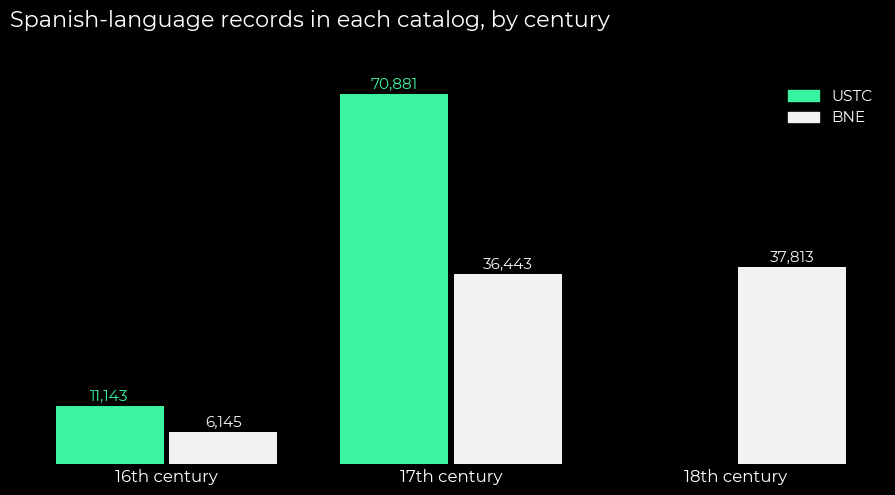

In [8]:
# Celda 8
# Figure 1: records of each catalog by century, USTC and BNE side by side:
labels = ["16th", "17th", "18th"]
fig, ax = plt.subplots(figsize=(9, 5))
for i, century in enumerate(labels):
    for name, offset, color in [("USTC", -0.2, GREEN), ("BNE", 0.2, WHITE)]:
        value = universe.loc[name].get(century, 0)
        if value > 0:
            ax.bar(i + offset, value, width=0.38, color=color)
            ax.text(i + offset, value + 1000, f"{value:,}", ha="center", fontsize=11, color=color)
ax.set_xticks(range(3))
ax.set_xticklabels([c + " century" for c in labels], fontsize=12)
ax.set_yticks([])
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.legend(handles=[Patch(color=GREEN, label="USTC"), Patch(color=WHITE, label="BNE")], frameon=False, fontsize=11)
fig.suptitle("Spanish-language records in each catalog, by century", fontsize=16, x=0.01, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGURES + "/1_universe.png", dpi=200)
plt.show()

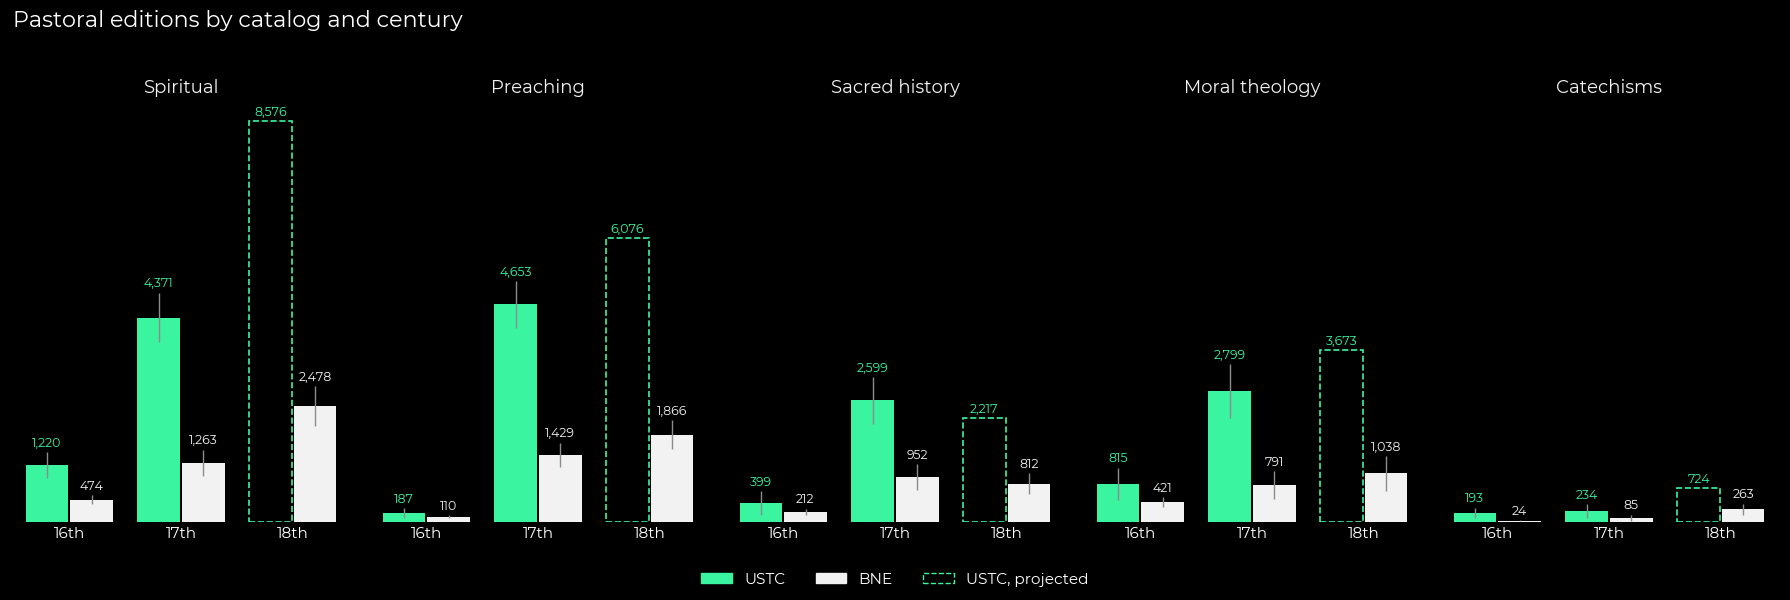

In [9]:
# Celda 9
# Figure 2: one panel per category; in each century the USTC next to the BNE, with the 95% interval as a thin line.
# The USTC eighteenth century is the projection of Celda 7, drawn as a dashed outline:
fig, axes = plt.subplots(1, len(PASTORAL), figsize=(18, 6), sharey=True)
for ax, category in zip(axes, PASTORAL):
    for i, century in enumerate(labels):
        for source, offset, color in [("ustc", -0.2, GREEN), ("bne", 0.2, WHITE)]:
            row = by_century[(by_century["catalog"] == NAMES[source]) & (by_century["century"] == century) &
                             (by_century["group"] == ENGLISH[category])]
            if len(row) == 1:
                value, low, high = row["editions"].iloc[0], row["low"].iloc[0], row["high"].iloc[0]
                ax.bar(i + offset, value, width=0.38, color=color)
                ax.vlines(i + offset, low, high, color=GRAY, linewidth=1)
                ax.text(i + offset, high + 120, f"{value:,}", ha="center", fontsize=9, color=color)
            else:
                value = projection.loc[projection["group"] == ENGLISH[category], "USTC 18th (projection)"].iloc[0]
                ax.bar(i + offset, value, width=0.38, facecolor="none", edgecolor=GREEN, linewidth=1.2, linestyle="--")
                ax.text(i + offset, value + 120, f"{value:,}", ha="center", fontsize=9, color=GREEN)
    ax.set_title(ENGLISH[category], fontsize=13, color=WHITE)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["16th", "17th", "18th"], fontsize=11)
    ax.set_yticks([])
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    ax.tick_params(axis="x", length=0)
fig.legend(handles=[Patch(color=GREEN, label="USTC"), Patch(color=WHITE, label="BNE"),
                    Patch(facecolor="none", edgecolor=GREEN, linestyle="--", label="USTC, projected")],
           loc="lower center", ncol=3, frameon=False, fontsize=11)
fig.suptitle("Pastoral editions by catalog and century", fontsize=16, x=0.01, ha="left")
fig.tight_layout(rect=[0, 0.07, 1, 0.95])
fig.savefig(FIGURES + "/2_editions_by_century.png", dpi=200)
plt.show()

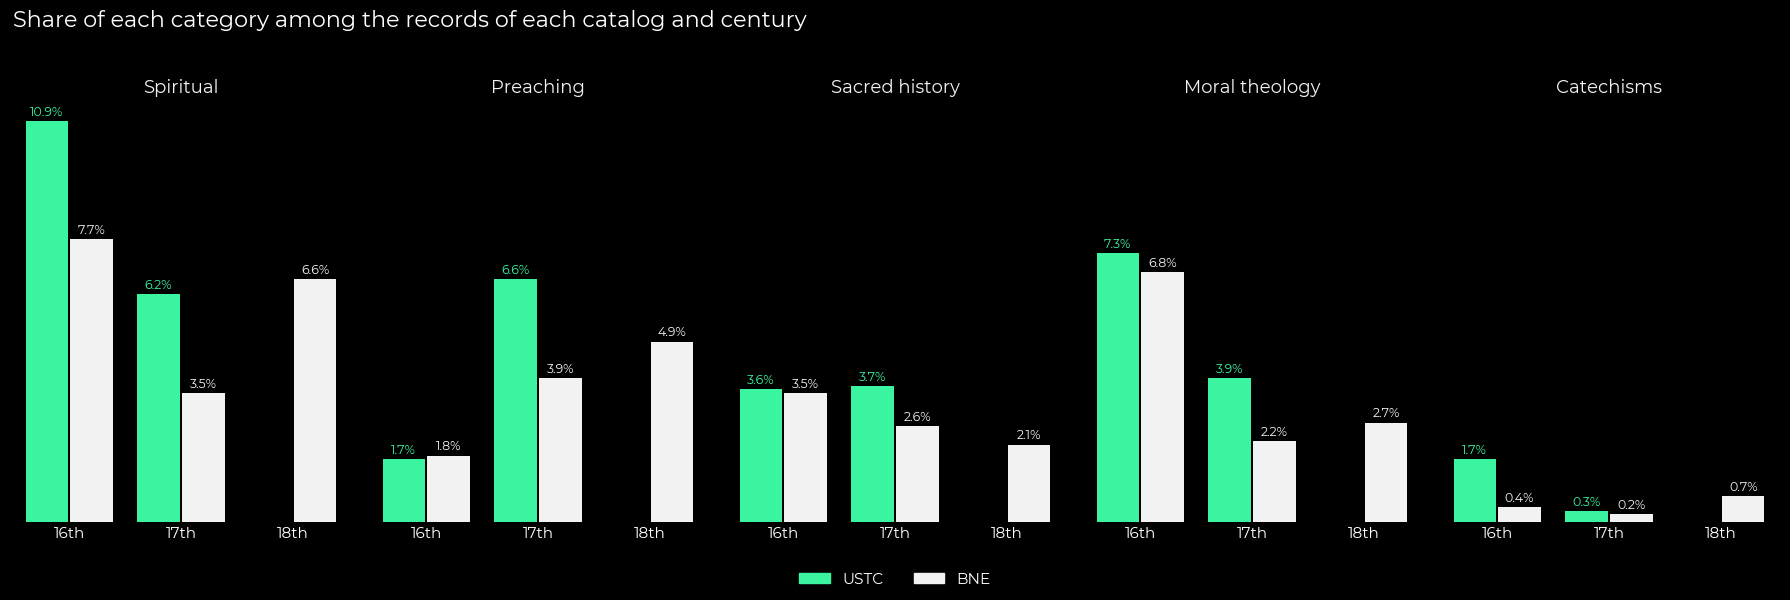

In [10]:
# Celda 10
# Figure 3: the same categories as a percent of all the records of that catalog and century:
fig, axes = plt.subplots(1, len(PASTORAL), figsize=(18, 6), sharey=True)
for ax, category in zip(axes, PASTORAL):
    for i, century in enumerate(labels):
        for source, offset, color in [("ustc", -0.2, GREEN), ("bne", 0.2, WHITE)]:
            row = by_century[(by_century["catalog"] == NAMES[source]) & (by_century["century"] == century) &
                             (by_century["group"] == ENGLISH[category])]
            if len(row) == 1:
                value = row["percent of records"].iloc[0]
                ax.bar(i + offset, value, width=0.38, color=color)
                ax.text(i + offset, value + 0.15, f"{value:.1f}%", ha="center", fontsize=9, color=color)
    ax.set_title(ENGLISH[category], fontsize=13, color=WHITE)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["16th", "17th", "18th"], fontsize=11)
    ax.set_yticks([])
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    ax.tick_params(axis="x", length=0)
fig.legend(handles=[Patch(color=GREEN, label="USTC"), Patch(color=WHITE, label="BNE")],
           loc="lower center", ncol=2, frameon=False, fontsize=11)
fig.suptitle("Share of each category among the records of each catalog and century", fontsize=16, x=0.01, ha="left")
fig.tight_layout(rect=[0, 0.07, 1, 0.95])
fig.savefig(FIGURES + "/3_shares_by_century.png", dpi=200)
plt.show()

## 5. What changes with books of 48 pages or more?

---

## 5. ¿Qué cambia con los libros de 48 páginas o más?

In [11]:
# Celda 11
# All records and books of 48 pages or more, for each catalog over all its centuries:
rows = []
for source in CENTURIES:
    records = catalog["century"].isin(CENTURIES[source]) & (catalog["source"] == source)
    long_total = (records & catalog["long"]).sum()
    for name, categories in [("Pastoral", PASTORAL)] + [(ENGLISH[c], [c]) for c in PASTORAL]:
        total, margin = estimate(categories, source, CENTURIES[source])
        long, long_margin = estimate(categories, source, CENTURIES[source], "long")
        rows.append({"catalog": NAMES[source], "group": name,
                     "all: editions": round(total), "all: percent": round(100 * total / records.sum(), 1),
                     f"{MIN_PAGES}+: editions": round(long), f"{MIN_PAGES}+: percent": round(100 * long / long_total, 1)})
by_length = pd.DataFrame(rows)
by_length.to_csv("results/estimates_by_length.csv", index=False)
by_length

,catalog,group,all: editions,all: percent,48+: editions,48+: percent
0,USTC,Pastoral,17470,21.3,9359,35.8
1,USTC,Spiritual,5591,6.8,3264,12.5
2,USTC,Preaching,4840,5.9,1667,6.4
3,USTC,Sacred history,2998,3.7,1567,6.0
4,USTC,Moral theology,3614,4.4,2604,10.0
5,USTC,Catechisms,427,0.5,257,1.0
6,BNE,Pastoral,12218,15.2,7059,24.4
7,BNE,Spiritual,4215,5.2,2485,8.6
8,BNE,Preaching,3405,4.2,1531,5.3
9,BNE,Sacred history,1977,2.5,1226,4.2


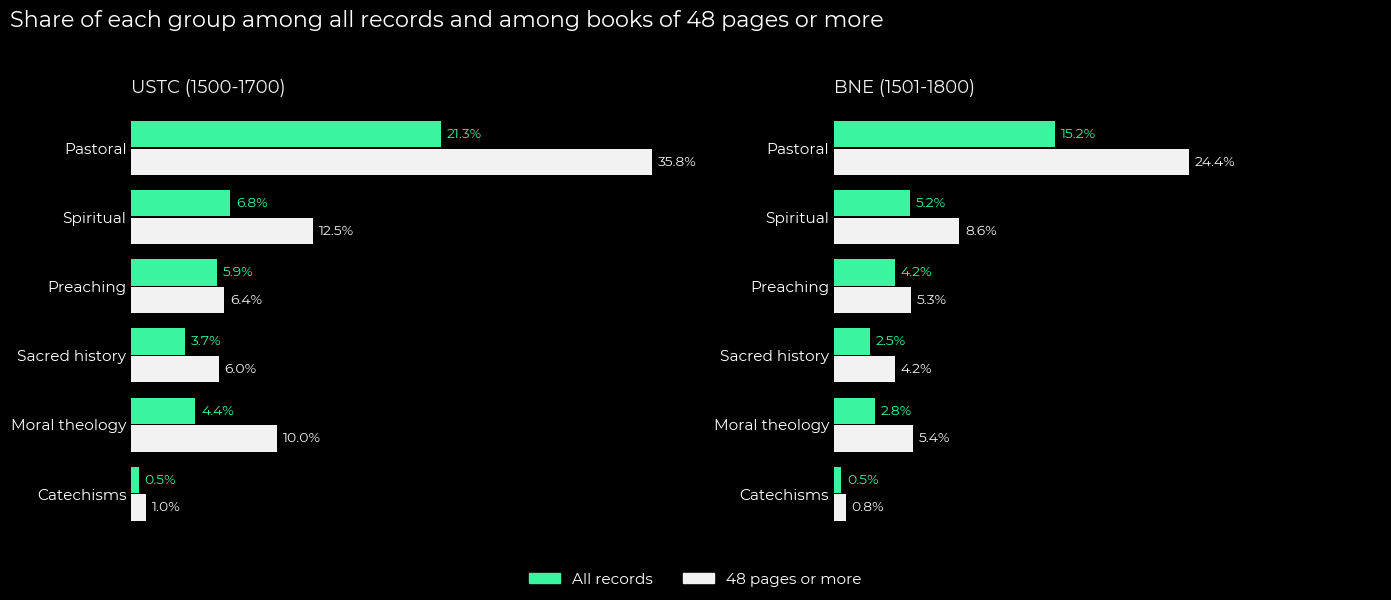

In [12]:
# Celda 12
# Figure 4: share of each group among all records (green) and among books of 48 pages or more (white), one panel per catalog:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, source in zip(axes, ["ustc", "bne"]):
    plot_data = by_length[by_length["catalog"] == NAMES[source]].iloc[::-1]
    y = range(len(plot_data))
    ax.barh([i + 0.2 for i in y], plot_data["all: percent"], height=0.38, color=GREEN)
    ax.barh([i - 0.2 for i in y], plot_data[f"{MIN_PAGES}+: percent"], height=0.38, color=WHITE)
    for i, (a, b) in enumerate(zip(plot_data["all: percent"], plot_data[f"{MIN_PAGES}+: percent"])):
        ax.text(a + 0.4, i + 0.2, f"{a:.1f}%", va="center", fontsize=10, color=GREEN)
        ax.text(b + 0.4, i - 0.2, f"{b:.1f}%", va="center", fontsize=10, color=WHITE)
    ax.set_yticks(list(y))
    ax.set_yticklabels(plot_data["group"], fontsize=11)
    ax.set_xticks([])
    years = "1500-1700" if source == "ustc" else "1501-1800"
    ax.set_title(f"{NAMES[source]} ({years})", fontsize=13, color=WHITE, loc="left")
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.legend(handles=[Patch(color=GREEN, label="All records"), Patch(color=WHITE, label=f"{MIN_PAGES} pages or more")],
           loc="lower center", ncol=2, frameon=False, fontsize=11)
fig.suptitle(f"Share of each group among all records and among books of {MIN_PAGES} pages or more", fontsize=16, x=0.01, ha="left")
fig.tight_layout(rect=[0, 0.07, 1, 0.95])
fig.savefig(FIGURES + "/4_by_length.png", dpi=200)
plt.show()

## 6. What about the other categories and the Jesuit authors?

---

## 6. ¿Y las demás categorías y los autores jesuitas?

In [13]:
# Celda 13
# Percent of each category in each catalog, over all its centuries:
by_column = pd.DataFrame(index=[ENGLISH[c] for c in CATEGORIES])
for source in CENTURIES:
    records = catalog["century"].isin(CENTURIES[source]) & (catalog["source"] == source)
    long_total = (records & catalog["long"]).sum()
    by_column[NAMES[source]] = [round(100 * estimate([c], source, CENTURIES[source])[0] / records.sum(), 1) for c in CATEGORIES]
    by_column[f"{NAMES[source]} {MIN_PAGES}+"] = [round(100 * estimate([c], source, CENTURIES[source], "long")[0] / long_total, 1)
                                                for c in CATEGORIES]
by_column = by_column.sort_values("BNE", ascending=False)
by_column.to_csv("results/categories_by_column.csv")
by_column

,USTC,USTC 48+,BNE,BNE 48+
Not religious,47.3,42.0,59.0,54.9
Church government and legal,28.4,19.4,22.5,18.8
Spiritual,6.8,12.5,5.2,8.6
Preaching,5.9,6.4,4.2,5.3
Liturgy,2.8,1.8,3.1,1.2
Moral theology,4.4,10.0,2.8,5.4
Sacred history,3.7,6.0,2.5,4.2
Catechisms,0.5,1.0,0.5,0.8
Bible,0.2,0.5,0.3,0.6
Theology,0.0,0.0,0.0,0.0


In [14]:
# Celda 14
# Share of Jesuit authors among editions with an author, for each catalog over all its centuries:
rows = []
for source in CENTURIES:
    for name, categories in [("Pastoral", PASTORAL), ("Spiritual", ["espiritual"]), ("Preaching", ["predicable"])]:
        with_author, margin = estimate(categories, source, CENTURIES[source], "with_author")
        jesuit, jesuit_margin = estimate(categories, source, CENTURIES[source], "jesuit")
        rows.append({"catalog": NAMES[source], "group": name, "editions with author": round(with_author),
                     "by Jesuits": round(jesuit), "percent": round(100 * jesuit / with_author, 1)})
jesuits = pd.DataFrame(rows)
jesuits.to_csv("results/jesuits.csv", index=False)
jesuits

,catalog,group,editions with author,by Jesuits,percent
0,USTC,Pastoral,15345,2244,14.6
1,USTC,Spiritual,5128,822,16.0
2,USTC,Preaching,4528,619,13.7
3,BNE,Pastoral,10487,1372,13.1
4,BNE,Spiritual,3304,530,16.0
5,BNE,Preaching,3198,308,9.6


In [15]:
# Celda 15
# How the model's classes compare with the lexicon in the sample (rows: lexicon; columns: model):
labeled["llm_class"] = "not pastoral"
labeled.loc[labeled["llm_category"].isin(PASTORAL), "llm_class"] = "other pastoral"
labeled.loc[labeled["llm_category"] == "espiritual", "llm_class"] = "spiritual"
pd.crosstab(labeled["lexicon_class"], labeled["llm_class"])

llm_class,not pastoral,other pastoral,spiritual
lexicon_class,,,
none,2705,127,63
other_pastoral,424,984,68
spiritual,433,152,851


## 7. Does the classifier of notebook 7c help?

---

## 7. ¿Ayuda el clasificador del notebook 7c?

In [16]:
# Celda 16
# Check with the classifier of notebook 7c: its count in each cell, corrected by the average difference between the model and
# the classifier (out of fold) in the sample of that cell. It gives estimates close to the ones above, with intervals no narrower,
# so the figures of this notebook come from the sample alone:
def estimate_with_classifier(categories, source, centuries):
    total = 0
    variance = 0
    for century in centuries:
        for stratum in ["spiritual", "other_pastoral", "none"]:
            cell = catalog[(catalog["source"] == source) & (catalog["century"] == century) & (catalog["lexicon_class"] == stratum)]
            rows = labeled[(labeled["source"] == source) & (labeled["century"] == century) & (labeled["lexicon_class"] == stratum)]
            difference = rows["llm_category"].isin(categories).astype(int) - rows["ml_category"].isin(categories).astype(int)
            total = total + cell["ml_category"].isin(categories).sum() + len(cell) * difference.mean()
            variance = variance + len(cell) ** 2 * difference.var() / len(rows)
    return total, 1.96 * math.sqrt(variance)

rows = []
for source in CENTURIES:
    for century in CENTURIES[source]:
        sample_only, margin = estimate(["espiritual"], source, [century])
        with_classifier, classifier_margin = estimate_with_classifier(["espiritual"], source, [century])
        rows.append({"catalog": NAMES[source], "century": century, "spiritual, sample": round(sample_only),
                     "± sample": round(margin), "spiritual, classifier": round(with_classifier),
                     "± classifier": round(classifier_margin)})
pd.DataFrame(rows)

,catalog,century,"spiritual, sample",± sample,"spiritual, classifier",± classifier
0,USTC,16th,1220,277,1258,361
1,USTC,17th,4371,534,4328,583
2,BNE,16th,474,89,491,86
3,BNE,17th,1263,281,1408,256
4,BNE,18th,2478,421,2280,435


## 8. How many of these books has the BNE digitized?

A BNE record counts as digitized when its `url` field links to the Biblioteca Digital Hispánica (`bdh-rd.bne.es`). This means
digitized by the BNE, not that no digital copy exists elsewhere. For all records the count is exact; for each group it is an
estimate, made as above: in each cell, the share of the sample that is in the group and digitized, times the records of the cell.

---

## 8. ¿Cuántos de estos libros digitalizó la BNE?

Un registro de la BNE cuenta como digitalizado cuando su campo `url` enlaza con la Biblioteca Digital Hispánica
(`bdh-rd.bne.es`). Quiere decir digitalizado por la BNE, no que no exista una copia digital en otro lado. Para el total de
registros la cifra es exacta; para cada grupo es una estimación, hecha como arriba: en cada casilla, la proporción de la muestra
que está en el grupo y digitalizada, por los registros de la casilla.

In [17]:
# Celda 17
# Mark the BNE records with a link to the Biblioteca Digital Hispánica; links to other libraries or to BNE pages don't count.
# The ids come with a leading space: " 991061093350308606" -> "991061093350308606":
bne_links = pd.read_csv(BNE_CATALOG, sep=";", dtype=str, usecols=["id", "url"])
bne_links["id"] = bne_links["id"].str.strip()
digitized_ids = set(bne_links.loc[bne_links["url"].str.contains("bdh-rd.bne.es", na=False), "id"])
for table in [catalog, labeled]:
    table["digitized"] = (table["source"] == "bne") & table["id"].isin(digitized_ids)
bne = (catalog["source"] == "bne") & catalog["century"].isin(CENTURIES["bne"])
print("BNE records:", bne.sum(), "| digitized:", (bne & catalog["digitized"]).sum(),
      "| digitized in the sample:", labeled["digitized"].sum())

BNE records: 80401 | digitized: 26289 | digitized in the sample: 1199


In [18]:
# Celda 18
# Digitized BNE records by century and group. "All records" is a count; the groups are estimates with a 95% interval:
rows = []
for period, centuries in [("16th", ["16th"]), ("17th", ["17th"]), ("18th", ["18th"]), ("1501-1800", CENTURIES["bne"])]:
    records = bne & catalog["century"].isin(centuries)
    digitized = (records & catalog["digitized"]).sum()
    rows.append({"period": period, "group": "All records", "editions": records.sum(), "digitized": digitized,
                 "low": digitized, "high": digitized, "percent digitized": round(100 * digitized / records.sum(), 1)})
    for name, categories in [("Pastoral", PASTORAL)] + [(ENGLISH[c], [c]) for c in PASTORAL]:
        total = estimate(categories, "bne", centuries)[0]
        digitized, margin = estimate(categories, "bne", centuries, "digitized")
        rows.append({"period": period, "group": name, "editions": round(total), "digitized": round(digitized),
                     "low": round(digitized - margin), "high": round(digitized + margin),
                     "percent digitized": round(100 * digitized / total, 1)})
bne_digitized = pd.DataFrame(rows)
bne_digitized.to_csv("results/bne_digitized.csv", index=False)
bne_digitized[bne_digitized["period"] == "1501-1800"]

,period,group,editions,digitized,low,high,percent digitized
21,1501-1800,All records,80401,26289,26289,26289,32.7
22,1501-1800,Pastoral,12218,4049,3569,4530,33.1
23,1501-1800,Spiritual,4215,1476,1135,1818,35.0
24,1501-1800,Preaching,3405,1294,1027,1561,38.0
25,1501-1800,Sacred history,1977,549,387,711,27.8
26,1501-1800,Moral theology,2250,561,381,741,24.9
27,1501-1800,Catechisms,372,169,73,266,45.6


In [19]:
# Celda 19
# Percent digitized, by group and century:
bne_digitized.pivot_table(index="group", columns="period", values="percent digitized", sort=False)

period,16th,17th,18th,1501-1800
group,,,,
All records,45.8,26.8,36.3,32.7
Pastoral,59.0,17.3,39.3,33.1
Spiritual,65.8,26.9,33.3,35.0
Preaching,62.2,11.8,56.6,38.0
Sacred history,65.2,15.4,32.5,27.8
Moral theology,47.2,12.7,25.2,24.9
Catechisms,61.3,27.5,50.0,45.6
